# XGBoost

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

In [12]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Clean and Load the Data

In [13]:
# fetch dataset 
chronic_kidney_disease = fetch_ucirepo(id=336) 
  
# data (as pandas dataframes) 
X = chronic_kidney_disease.data.features 
y = chronic_kidney_disease.data.targets 

In [14]:
df = pd.concat([X, y], axis=1)

# Column groups 
ordinal_cols = ['sg', 'al', 'su']
num_cols = ['age', 'bp', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']
cat_cols = ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

# Clean string columns
str_cols = df.select_dtypes(exclude='number').columns.tolist()
for c in str_cols:
    df[c] = df[c].str.strip().replace({'?': np.nan, '': np.nan})

# Fix the typos
df.loc[df['pot'] > 10, 'pot'] = np.nan
df.loc[df['sod'] < 100, 'sod'] = np.nan

print(df['class'].unique())

<ArrowStringArray>
['ckd', 'notckd']
Length: 2, dtype: str


# Encode Features and Target

In [15]:
y = (df['class'] == 'ckd').astype(int)
X = df.drop(columns=['class'])

for c in cat_cols:
    X[c] = X[c].astype('category').cat.codes.replace(-1, np.nan)

X[ordinal_cols] = X[ordinal_cols].apply(pd.to_numeric, errors='coerce')
print(X.dtypes)

age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc      float64
pc       float64
pcc      float64
ba       float64
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn      float64
dm       float64
cad      float64
appet    float64
pe       float64
ane      float64
dtype: object


# Train Test Split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, stratify=y, random_state=42
)

# Baseline Model

              precision    recall  f1-score   support

     not CKD       1.00      1.00      1.00        30
         CKD       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

ROC AUC: 1.0


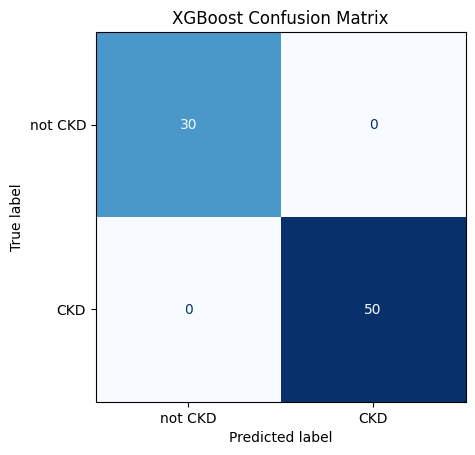

In [17]:
model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    eval_metric='logloss',
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['not CKD', 'CKD']))
print('ROC AUC:', roc_auc_score(y_test, y_proba))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['not CKD', 'CKD'],
    cmap='Blues',
    colorbar=False
)
plt.title('XGBoost Confusion Matrix')
plt.show()

# Cross Validation

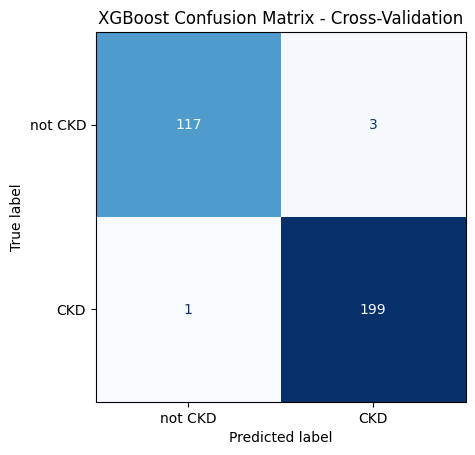

              precision    recall  f1-score   support

     not CKD       0.99      0.97      0.98       120
         CKD       0.99      0.99      0.99       200

    accuracy                           0.99       320
   macro avg       0.99      0.98      0.99       320
weighted avg       0.99      0.99      0.99       320



In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_cv_pred = cross_val_predict(model, X_train, y_train, cv=cv)

ConfusionMatrixDisplay.from_predictions(
    y_train, y_cv_pred,
    display_labels=['not CKD', 'CKD'],
    cmap='Blues',
    colorbar=False
)
plt.title('XGBoost Confusion Matrix - Cross-Validation')
plt.show()

print(classification_report(y_train, y_cv_pred, target_names=['not CKD', 'CKD']))

# Check if Missing Data Affects Model

In [19]:
scores_a = cross_val_score(model, X, y, cv=cv, scoring='roc_auc')

# Hide the Missing Data
pipe_imputed = make_pipeline(SimpleImputer(strategy='median'), model)
scores_b = cross_val_score(pipe_imputed, X, y, cv=cv, scoring='roc_auc')

print(f'Native NaN handling: {scores_a.mean():.3f}')
print(f'Median imputed:      {scores_b.mean():.3f}')

Native NaN handling: 1.000
Median imputed:      0.998


# Feature Importance

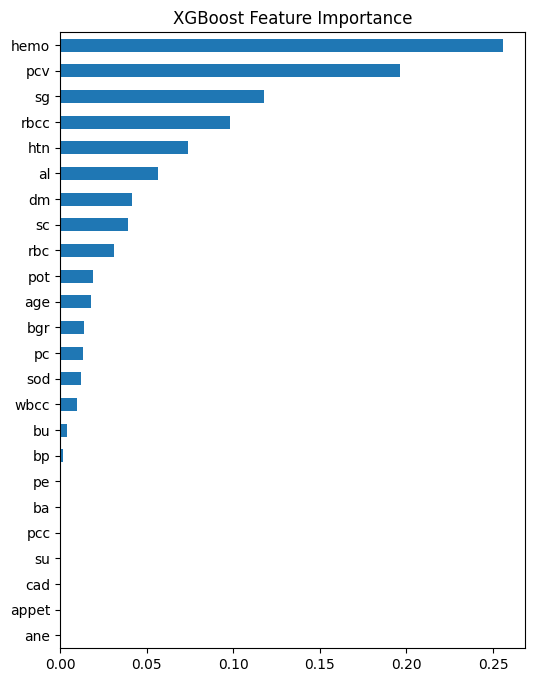

In [20]:
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(6,8), title='XGBoost Feature Importance')
plt.show()